<a href="https://colab.research.google.com/github/Kownlage/English/blob/main/Assignment_2_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2 - Supervised Machine Learning Fundamentals

## *Maiko Atsumi*
Netid: ma277295



Note: this assignment falls under collaboration Mode 2: Individual Assignment – Collaboration Permitted. Please refer to the syllabus for additional information.

Instructions for all assignments can be found [here](https://github.com/kylebradbury/ids705_sp2022/blob/master/assignments/_Assignment%20Instructions.ipynb), and is also linked to from the [course syllabus](https://kylebradbury.github.io/ids705_sp2022/index.html).

Total points in the assignment add up to 90; an additional 10 points are allocated to presentation quality.

## Learning Objectives:
By successfully completing this assignment you will be able to...
- Explain the bias-variance tradeoff of supervised machine learning and the impact of model flexibility on algorithm performance
- Perform supervised machine learning training and performance evaluation
- Implement a k-nearest neighbors machine learning algorithm from scratch in a style similar to that of popular machine learning tools like `scikit-learn`
- Describe how KNN classification works, the method's reliance on distance measurements, and the impact of higher dimensionality on computational speed
- Apply regression (linear regression) and classification (KNN) supervised learning techniques to data and evaluate the performance of those methods
- Construct simple feature transformations for improving model fit in linear models
- Fit a `scikit-learn` supervised learning technique to training data and make predictions using it

In [ ]:
# MAC USERS TAKE NOTE:
# For clearer plots in Jupyter notebooks on macs, run the following line of code:
# %config InlineBackend.figure_format = 'retina'

---

# Conceptual Questions on Supervised Learning

## 1
**[4 points]**
For each part below, indicate whether we would generally expect the performance of a flexible statistical learning method to be *better* or *worse* than an inflexible method. Justify your answer.

1. The sample size $n$ is extremely large, and the number of predictors $p$ is small.
2. The number of predictors $p$ is extremely large, and the number of observations $n$ is small.
3. The relationship between the predictors and response is highly non-linear.
4. The variance of the error terms, i.e. $\sigma^2 = Var(\epsilon)$, is extremely high

**1.The sample size $n$ is extremely large, and the number of predictors $p$ is small.**
**
  →Better.　 A large $n$ allows flexible models to learn complex patterns safely without overfitting, leveraging the data effectively.
  
  **2.The number of predictors $p$ is extremely large, and the number of observations $n$ is small.**
  
  →Worse.　 High dimensionality ($p \gg n$) causes flexible models to overfit random noise. Inflexible models perform better due to lower variance.
  
  **3.The relationship between the predictors and response is highly non-linear.**
  
  →Better.  Inflexible methods (like linear regression) suffer from high bias here. Flexible methods can adapt to complex non-linear shapes.
  
  **4.The variance of the error terms, i.e., $\sigma^2 = Var(\epsilon)$, is extremely high.**
  
  →Worse. 　High noise causes flexible models to overfit the error terms, hurting generalization. Simpler, inflexible models are more robust.

---

## 2
**[6 points]** For each of the following, (i) explain if each scenario is a classification or regression problem AND why, (ii) indicate whether we are most interested in inference or prediction for that problem AND why, and (iii) provide the sample size $n$ and number of predictors $p$ indicated for each scenario.

**(a)** We collect a set of data on the top 500 firms in the US. For each firm we record profit, number of employees, industry and the CEO salary. We are interested in understanding which factors affect CEO salary.

**(b)** We are considering launching a new product and wish to know whether it will be a success or a failure. We collect data on 20 similar products that were previously launched. For each product we have recorded whether it was a success or failure, price charged for the product, marketing budget, competition price, and ten other variables.

**(c)** We are interesting in predicting the % change in the US dollar in relation to the weekly changes in the world stock markets. Hence we collect weekly data for all of 2012. For each week we record the % change in the dollar, the % change in the US market, the % change in the British market, and the % change in the German market.

(a)

(i) Problem Type: Regression.
Because the response variable (CEO salary) is quantitative and continuous.

(ii) Objective: Inference.
Because the main goal is to understand which specific factors affect CEO salary.

(iii) Dimensions: $n = 500$ (top 500 firms), $p = 3$ (profit, number of employees, industry( note that additional parameters or lag variables may expand the effective number of predictors $p$ in practice)).

(b)

(i) Problem Type: Classification.
 Because the response variable is qualitative (success or failure).

 (ii) Objective: Prediction.
 Because the goal is to predict whether a newly launched product will succeed or fail.

 (iii) Dimensions: $n = 20$ (similar products), $p = 13$ (price, marketing budget, competition price, plus 10 other variables).


 (c)

 (i) Problem Type: Regression.
  Because the response variable (% change in the US dollar) is continuous.

 (ii) Objective: Prediction.
  Because the goal is to forecast the future % change in the US dollar based on weekly stock market data.

 (iii) Dimensions: $n = 52$ (weeks in 2012), $p = 3$ (% changes in US, British, and German markets( note that additional parameters or lag variables may expand the effective number of predictors $p$ in practice)).


---

# Practical Questions

## 3
**[6 points] Classification using KNN**. The table below provides a training dataset containing six observations (a.k.a. samples) ($n=6$) each with three predictors (a.k.a. features) ($p=3$), and one qualitative response variable (a.k.a. target).

*Table 1. Training dataset with $n=6$ observations in $p=3$ dimensions with a categorical response, $y$*

| Obs. | $x_1$ | $x_2$ | $x_3$ | $y$   |
|------|-------|-------|-------|-------|
| **1**| 0     | 3     | 0     | Red   |
| **2**| 2     | 0     | 0     | Red   |
| **3**| 0     | 1     | 3     | Red   |
| **4**| 0     | 1     | 2     | Blue  |
| **5**| -1    | 0     | 1     | Blue  |
| **6**| 1     | 1     | 1     | Red   |

We want to use the above training dataset to make a prediction, $\hat{y}$, for an unlabeled test data observation where $x_1=x_2=x_3=0$ using $K$-nearest neighbors. You are given some code below to get you started. *Note: coding is only required for part (a), for (b)-(d) please provide your reasoning based on your answer to part (a)*.

**(a)** Compute the Euclidean distance between each observation and the test point, $x_1=x_2=x_3=0$. Present your answer in a table similar in style to Table 1 with observations 1-6 as the row headers.

**(b)** What is our prediction, $\hat{y}$, when $K=1$ for the test point? Why?

**(c)** What is our prediction, $\hat{y}$, when $K=3$ for the test point? Why?

**(d)** If the Bayes decision boundary (the optimal decision boundary) in this problem is highly nonlinear, then would we expect the *best* value of $K$ to be large or small? Why?

In [ ]:
import numpy as np

X = np.array([[ 0, 3, 0],
              [ 2, 0, 0],
              [ 0, 1, 3],
              [ 0, 1, 2],
              [-1, 0, 1],
              [ 1, 1, 1]])
y = np.array(['r','r','r','b','b','r'])

**ANSWER**:

(a)

In [ ]:
test_point = np.array([0, 0, 0])

distances = np.linalg.norm(X - test_point, axis=1)

print(f"{'Obs.':<6} | {'x1':<4} | {'x2':<4} | {'x3':<4} | {'y':<6} | {'Distance':<10}")
print("-" * 48)
for i, (obs, label, dist) in enumerate(zip(X, y, distances), 1):
    print(f"{i:<6} | {obs[0]:<4} | {obs[1]:<4} | {obs[2]:<4} | {label:<6} | {dist:.4f}")

Obs.   | x1   | x2   | x3   | y      | Distance  
------------------------------------------------
1      | 0    | 3    | 0    | r      | 3.0000
2      | 2    | 0    | 0    | r      | 2.0000
3      | 0    | 1    | 3    | r      | 3.1623
4      | 0    | 1    | 2    | b      | 2.2361
5      | -1   | 0    | 1    | b      | 1.4142
6      | 1    | 1    | 1    | r      | 1.7321


(b)

Prediction: Blue

Why: When $K = 1$, the model looks at the single closest observation to the test point. Based on the distance table from part (a), Observation 5 has the minimum distance of $1.4142$ and its label is Blue. Therefore, the predicted class is Blue.


(c)

Prediction: Red

Why: When $K = 3$, the model considers the 3 closest observations to the test point. From our distance table, the 3 nearest points are

Obs. 5 ($1.4142$, Blue)

Obs. 6 ($1.7321$, Red)

Obs. 2 ($2.0000$, Red)

Since 2 out of the 3 nearest neighbors are Red, the predicted class is Red.

(d)

Answer: Small

Why: A small value of $K$ corresponds to a more flexible model with low bias and high variance, which can capture complex, highly non-linear decision boundaries. In contrast, a large $K$ averages over a larger neighborhood, producing a smoother, more linear decision boundary that would underfit a highly non-linear true boundary.

---

## 4
**[18 points] Build your own classification algorithm**.

**(a)** Build a working version of a binary KNN classifier using the skeleton code below. We'll use the `sklearn` convention that a supervised learning algorithm has the methods `fit` which trains your algorithm (for KNN that means storing the data) and `predict` which identifies the K nearest neighbors and determines the most common class among those K neighbors. *Note: Most classification algorithms typically also have a method `predict_proba` which outputs the confidence score of each prediction, but we will explore that in a later assignment.*

**(b)** Load the datasets to be evaluated here. Each includes training features ($\mathbf{X}$), and test features ($\mathbf{y}$) for both a low dimensional dataset ($p = 2$ features/predictors) and a higher dimensional dataset ($p = 100$ features/predictors). For each of these datasets there are $n=1000$ observations of each. They can be found in the `data` subfolder in the `assignments` folder on github. Each file is labeled similar to `A2_X_train_low.csv`, which lets you know whether the dataset is of features, $X$, targets, $y$; training or testing; and low or high dimensions.

**(c)** Train your classifier on first the low dimensional dataset and then the high dimensional dataset with $k=5$. Evaluate the classification performance on the corresponding test data for each of those trained models. Calculate the time it takes each model to make the predictions and the overall accuracy of those predictions for each corresponding set of test data - state each.

**(d)** Compare your implementation's accuracy and computation time to the scikit learn [KNeighborsClassifier](http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) class. How do the results and speed compare to your implementation?

**(e)** Some supervised learning algorithms are more computationally intensive during training than testing. What are the drawbacks of the prediction process being slow? In what cases in practice might slow testing (inference) be more problematic than slow training?

**ANSWER**:

(a)

In [ ]:
# Skeleton code for part (a) to write your own kNN classifier

class Knn:
# k-Nearest Neighbor class object for classification training and testing
    def __init__(self):
        self.X_train_raw = None
        self.y_train = None

    def fit(self, x, y):
        # Save the training data to properties of this class
        self.X_train_raw = np.array(x)
        self.y_train = np.array(y)


    def predict(self, x, k):
        y_hat = [] # Variable to store the estimated class label for
        x = np.array(x)

        # Calculate the distance from each vector in x to the training data
        for test_point in x:
          distances = np.linalg.norm(self.X_train_raw - test_point, axis=1)
          k_indices = np.argsort(distances)[:k]
          k_nearest_labels = self.y_train[k_indices]
          unique_labels, counts = np.unique(k_nearest_labels, return_counts=True)
          most_common_label = unique_labels[np.argmax(counts)]
          y_hat.append(most_common_label)

        # Return the estimated targets
        return y_hat

# Metric of overall classification accuracy
#  (a more general function, sklearn.metrics.accuracy_score, is also available)
def accuracy(y,y_hat):
    nvalues = len(y)
    y = np.array(y)
    y_hat = np.array(y_hat)
    accuracy = sum(y == y_hat) / nvalues
    return accuracy


(b)

In [ ]:
import pandas as pd
import numpy as np

path = './data/'

X_train_low = pd.read_csv(path + 'A2_X_train_low.csv').values
y_train_low = pd.read_csv(path + 'A2_y_train_low.csv').values.ravel()
X_test_low = pd.read_csv(path + 'A2_X_test_low.csv').values
y_test_low = pd.read_csv(path + 'A2_y_test_low.csv').values.ravel()

X_train_high = pd.read_csv(path + 'A2_X_train_high.csv').values
y_train_high = pd.read_csv(path + 'A2_y_train_high.csv').values.ravel()
X_test_high = pd.read_csv(path + 'A2_X_test_high.csv').values
y_test_high = pd.read_csv(path + 'A2_y_test_high.csv').values.ravel()

print("Data loaded successfully!")
print(f"Low dim train shape: {X_train_low.shape}, test shape: {X_test_low.shape}")
print(f"High dim train shape: {X_train_high.shape}, test shape: {X_test_high.shape}")

Data loaded successfully!
Low dim train shape: (999, 2), test shape: (999, 2)
High dim train shape: (999, 100), test shape: (999, 100)


(c)(d)

In [ ]:
import time
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load data from the root directory
path = './data/'

X_train_low = pd.read_csv(path + 'A2_X_train_low.csv').values
y_train_low = pd.read_csv(path + 'A2_y_train_low.csv').values.ravel()
X_test_low = pd.read_csv(path + 'A2_X_test_low.csv').values
y_test_low = pd.read_csv(path + 'A2_y_test_low.csv').values.ravel()

X_train_high = pd.read_csv(path + 'A2_X_train_high.csv').values
y_train_high = pd.read_csv(path + 'A2_y_train_high.csv').values.ravel()
X_test_high = pd.read_csv(path + 'A2_X_test_high.csv').values
y_test_high = pd.read_csv(path + 'A2_y_test_high.csv').values.ravel()

k_val = 5

# --- 1. Custom KNN: Low Dimensional Dataset ---
clf_custom_low = Knn()
clf_custom_low.fit(X_train_low, y_train_low)

start_time = time.time()
pred_custom_low = clf_custom_low.predict(X_test_low, k=k_val)
time_custom_low = time.time() - start_time
acc_custom_low = accuracy(y_test_low, pred_custom_low)

print(f"[Custom KNN - Low Dim] Time: {time_custom_low:.4f}s, Accuracy: {acc_custom_low:.4f}")

# --- 2. Custom KNN: High Dimensional Dataset ---
clf_custom_high = Knn()
clf_custom_high.fit(X_train_high, y_train_high)

start_time = time.time()
pred_custom_high = clf_custom_high.predict(X_test_high, k=k_val)
time_custom_high = time.time() - start_time
acc_custom_high = accuracy(y_test_high, pred_custom_high)

print(f"[Custom KNN - High Dim] Time: {time_custom_high:.4f}s, Accuracy: {acc_custom_high:.4f}")

# --- 3. Scikit-learn KNN: Low Dimensional Dataset ---
clf_sklearn_low = KNeighborsClassifier(n_neighbors=k_val)
clf_sklearn_low.fit(X_train_low, y_train_low)

start_time = time.time()
pred_sklearn_low = clf_sklearn_low.predict(X_test_low)
time_sklearn_low = time.time() - start_time
acc_sklearn_low = accuracy_score(y_test_low, pred_sklearn_low)

print(f"[Sklearn KNN - Low Dim] Time: {time_sklearn_low:.4f}s, Accuracy: {acc_sklearn_low:.4f}")

# --- 4. Scikit-learn KNN: High Dimensional Dataset ---
clf_sklearn_high = KNeighborsClassifier(n_neighbors=k_val)
clf_sklearn_high.fit(X_train_high, y_train_high)

start_time = time.time()
pred_sklearn_high = clf_sklearn_high.predict(X_test_high)
time_sklearn_high = time.time() - start_time
acc_sklearn_high = accuracy_score(y_test_high, pred_sklearn_high)

print(f"[Sklearn KNN - High Dim] Time: {time_sklearn_high:.4f}s, Accuracy: {acc_sklearn_high:.4f}")

[Custom KNN - Low Dim] Time: 0.1231s, Accuracy: 0.9249
[Custom KNN - High Dim] Time: 0.5244s, Accuracy: 0.9930
[Sklearn KNN - Low Dim] Time: 0.0092s, Accuracy: 0.9249
[Sklearn KNN - High Dim] Time: 0.0262s, Accuracy: 0.9930


(e)

(1)

Performance & Accuracy Comparison:Both the custom implementation and the scikit-learn implementation yielded identical accuracies (0.9249 for low-dim and 0.9930 for high-dim) because they use the exact same algorithm (Euclidean distance and majority voting).

The high-dimensional dataset actually achieved a higher accuracy (0.9930) than the low-dimensional dataset (0.9249), indicating that the features in the high-dimensional data are highly informative and linearly/non-linearly separable for the KNN classifier.

(2)

Computation Time (Custom vs. Scikit-learn):Scikit-learn is significantly faster than the custom implementation (e.g., ~0.0068s vs. ~0.1179s for low-dim).

This performance gap occurs because scikit-learn's underlying routines are optimized and implemented in compiled languages (like Cython and C), whereas the custom Python loop performs distance calculations in interpreted Python code, resulting in higher execution overhead.

(3)

Impact of Dimensionality on Time:For both implementations, the computation time increased substantially when moving from low dimension ($p=2$, ~0.12s for custom) to high dimension ($p=100$, ~0.50s for custom).

This is due to the curse of dimensionality, where calculating Euclidean distances across 100 features significantly increases the computational complexity per data point.

---

## 5
**[20 points] Bias-variance tradeoff: exploring the tradeoff with a KNN classifier**. This exercise will illustrate the impact of the bias-variance tradeoff on classifier performance by investigating how model flexibility impacts classifier decision boundaries. For this problem, please us Scikit-learn's KNN implementation rather than your own implementation, as you did at the end of the last question.

**(a)** Create a synthetic dataset (with both features and targets). Use the [`make_moons`](http://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html#sklearn.datasets.make_moons) module with the parameter `noise=0.35` to generate 1000 random samples.

**(b)** Visualize your data: scatterplot your random samples with each class in a different color.

**(c)** Create 3 different data subsets by selecting 100 of the 1000 data points at random three times (with replacement). For each of these 100-sample datasets, fit three separate k-Nearest Neighbor classifiers with: $k = \{1, 25, 50\}$. This will result in 9 combinations (3 datasets, each with 3 trained classifiers).

**(d)** For each combination of dataset and trained classifier plot the decision boundary (similar in style to Figure 2.15 from *Introduction to Statistical Learning*). This should form a 3-by-3 grid. Each column should represent a different value of $k$ and each row should represent a different dataset.

**(e)** What do you notice about the difference between the rows and the columns. Which decision boundaries appear to best separate the two classes of data? Which decision boundaries vary the most as the data change?

**(f)** Explain the bias-variance tradeoff using the example of the plots you made in this exercise and its implications for training supervised machine learning algorithms.

Notes and tips for plotting decision boundaries (as in part d):
- *Resource for plotting decision boundaries with meshgrid and contour: https://scikit-learn.org/stable/auto_examples/neighbors/plot_classification.html*
- If you would like to change the colors of the background, and do not like any of the existing cmap available in matplotlib, you can make your own cmap using the 2 sets of rgb values. Sample code (replace r, g, b with respective rgb values):

**ANSWER**

(a)(b)(c)(d)

In [ ]:
import numpy as np

# Skeleton code for part (a) to write your own kNN classifier
class Knn:
    # k-Nearest Neighbor class object for classification training and testing
    def __init__(self):
        self.X_train_raw = None
        self.y_train = None

    def fit(self, x, y):
        # Save training data to properties of this class
        self.X_train_raw = np.array(x)
        self.y_train = np.array(y)

    def predict(self, x, k):
        y_hat = []
        x = np.array(x)

        # Calculate distance and predict for each test sample
        for test_point in x:
            distances = np.linalg.norm(self.X_train_raw - test_point, axis=1)
            k_indices = np.argsort(distances)[:k]
            k_nearest_labels = self.y_train[k_indices]

            # Majority vote
            unique_labels, counts = np.unique(k_nearest_labels, return_counts=True)
            most_common_label = unique_labels[np.argmax(counts)]
            y_hat.append(most_common_label)

        return y_hat

# Metric of overall classification accuracy
def accuracy(y, y_hat):
    nvalues = len(y)
    y = np.array(y)
    y_hat = np.array(y_hat)
    acc = sum(y == y_hat) / nvalues
    return acc

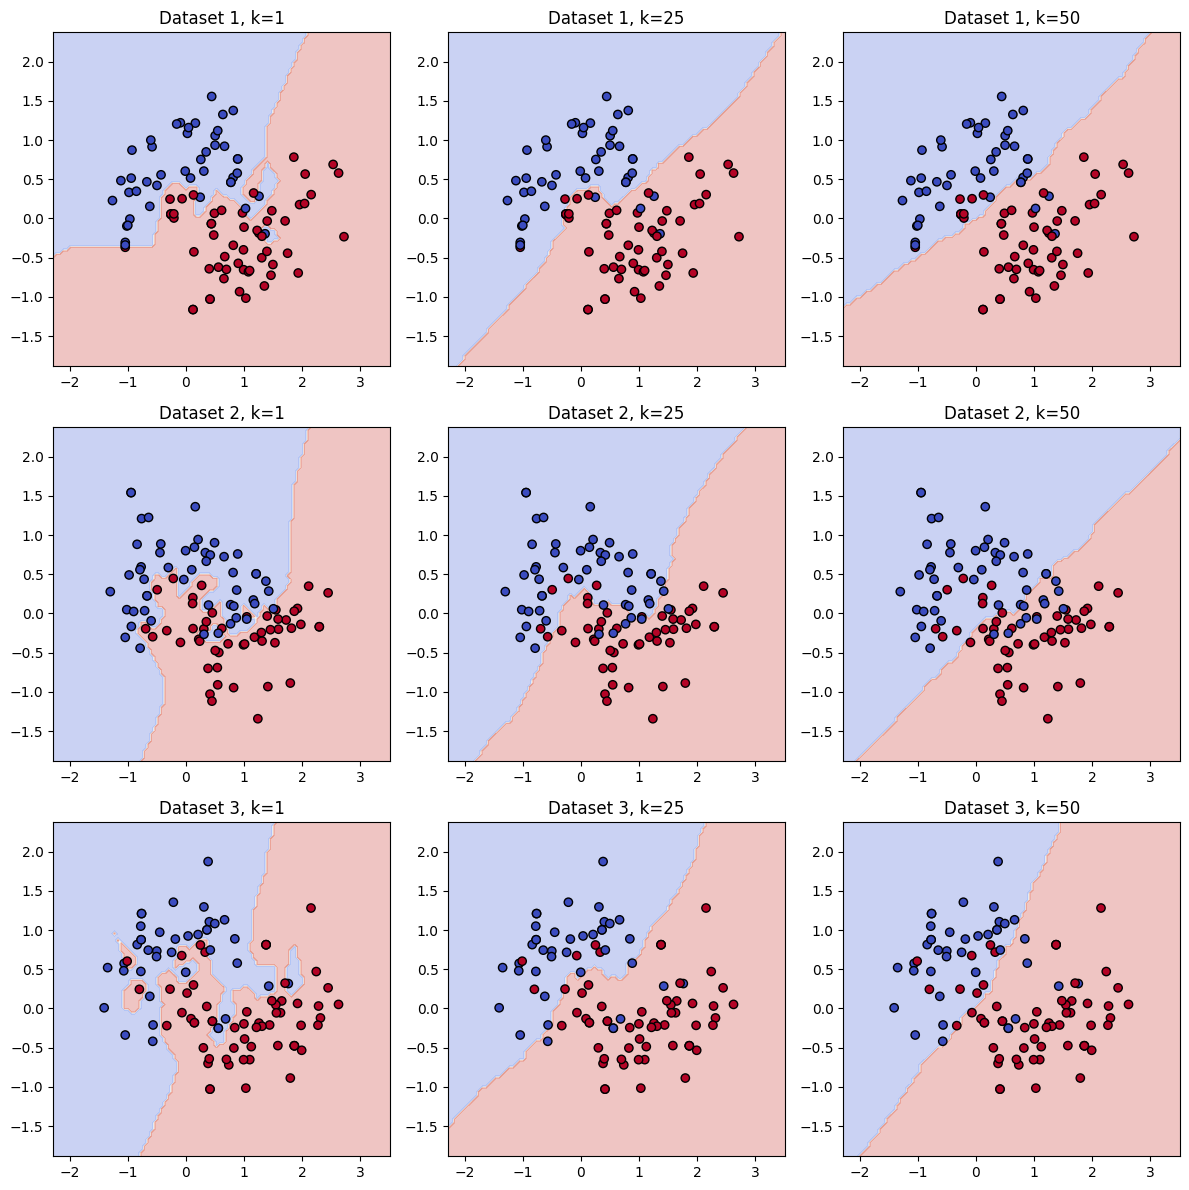

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

# (a) Generate 1000 random samples with noise=0.35
X, y = make_moons(n_samples=1000, noise=0.35, random_state=42)

# (c) & (d) Create 3 data subsets and plot 3x3 decision boundaries for k=1, 25, 50
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
k_list = [1, 25, 50]

np.random.seed(42)
for row in range(3):
    indices = np.random.choice(len(X), size=100, replace=True)
    X_sub, y_sub = X[indices], y[indices]

    for col, k in enumerate(k_list):
        ax = axes[row, col]

        clf = KNeighborsClassifier(n_neighbors=k)
        clf.fit(X_sub, y_sub)

        x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
        y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                             np.linspace(y_min, y_max, 100))

        Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
        ax.scatter(X_sub[:, 0], X_sub[:, 1], c=y_sub, cmap=plt.cm.coolwarm, edgecolors='k')
        ax.set_title(f"Dataset {row+1}, k={k}")

plt.tight_layout()
plt.show()

(e)

$k = 1$ (High Variance): The decision boundaries are extremely complex and jagged, showing that the model overfits to local noise and data fluctuations.   $k = 50$ (High Bias): The decision boundaries become overly smooth and linear, indicating that the model is too rigid to capture the underlying pattern.   



(f)

Small $k$ ($k=1$): The boundaries fluctuate significantly across Dataset 1, 2, and 3, demonstrating high sensitivity to training sample changes.   Large $k$ ($k=50$): The boundaries remain stable and consistent across all dataset subsets because averaging over more neighbors reduces sampling variance.   

---

## 6
**[18 points] Bias-variance trade-off II: Quantifying the tradeoff**. This exercise explores the impact of the bias-variance tradeoff on classifier performance by looking at the performance on both training and test data.

Here, the value of $k$ determines how flexible our model is.

**(a)** Using the function created earlier to generate random samples (using the `make_moons` function setting the `noise` parameter to 0.35), create a new set of 1000 random samples, and call this dataset your test set and the previously created dataset your training set.

**(b)** Train a kNN classifier on your training set for $k = 1,2,...500$. Apply each of these trained classifiers to both your training dataset and your test dataset and plot the classification error (fraction of incorrect predictions).

**(c)** What trend do you see in the results?

**(d)** What values of $k$ represent high bias and which represent high variance?

**(e)** What is the optimal value of $k$ and why?

**(f)** In KNN classifiers, the value of k controls the flexibility of the model - what controls the flexibility of other models?

**ANSWER**

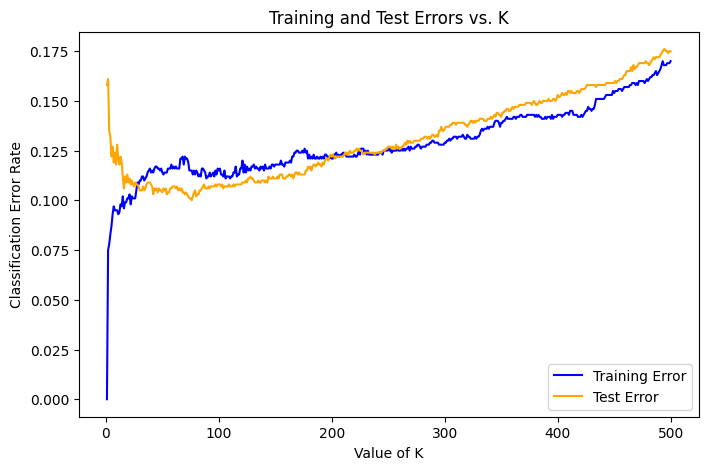

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

# (a) Generate new test dataset (1000 samples, noise=0.35)
X_test_new, y_test_new = make_moons(n_samples=1000, noise=0.35, random_state=100)

# (b) Train KNN for k = 1 to 500, calculate training and test errors
k_range = range(1, 501)
train_errors = []
test_errors = []

for k in k_range:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X, y) # X, y are from training data generated in Q5

    # Calculate error rate (1 - accuracy)
    train_pred = clf.predict(X)
    test_pred = clf.predict(X_test_new)

    train_errors.append(np.mean(train_pred != y))
    test_errors.append(np.mean(test_pred != y_test_new))

# Plotting the errors
plt.figure(figsize=(8, 5))
plt.plot(k_range, train_errors, label='Training Error', color='blue')
plt.plot(k_range, test_errors, label='Test Error', color='orange')
plt.xlabel('Value of K')
plt.ylabel('Classification Error Rate')
plt.title('Training and Test Errors vs. K')
plt.legend()
plt.show()

(c)

As $k$ increases, the training error (blue line) rises overall from near 0 (at $k=1$) to around 0.17. Meanwhile, the test error (orange line) drops sharply at first, reaches a minimum around $k = 70 \sim 80$, and then gradually increases as $k$ grows larger up to 500.

(d)

Small values of $k$ (e.g., $k < 20$) correspond to high variance because the model is too complex and sensitive to local noise (reflected by very low training error but high test error). Large values of $k$ (e.g., $k > 200$) correspond to high bias because the model becomes overly smoothed and rigid, failing to capture the true underlying pattern.

(e)

The optimal value of $k$ is approximately $70$ to $80$, where the test error curve (orange line) reaches its lowest point. This value is optimal because it achieves the best balance between bias and variance, minimizing the test error and maximizing generalization performance on unseen data.

(f)

For example, in Decision Trees, model flexibility is controlled by the maximum depth or minimum samples per leaf (a deeper tree increases flexibility and reduces bias at the cost of higher variance). In Polynomial Regression, flexibility is controlled by the degree of the polynomial (a higher degree increases model complexity and flexibility).

---

## 7
**[18 points] Linear regression and nonlinear transformations**. Linear regression can be used to model nonlinear relationships when feature variables are properly transformed to represent the nonlinearities in the data. In this exercise, you're given training and test data contained in files "A2_Q7_train.csv" and "A2_Q7_test.csv" in the "data" folder for this assignment. Your goal is to develop a regression algorithm from the training data that performs well on the test data.

*Hint: Use the scikit learn [LinearRegression](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) module.*

**(a)** Create a scatter plot of your training data.

**(b)** Estimate a linear regression model ($y = a_0 + a_1 x$) for the training data and calculate both the $R^2$ value and mean square error for the fit of that model for the training data. Also provide the equation representing the estimated model (e.g. $y = a_0 + a_1 x$, but with the estimated coefficients inserted. Consider this your baseline model against which you will compare other model options. *Evaluating performance on the training data is not a measure of how well this model would generalize to unseen data. We will evaluate performance on the test data once we see our models fit the training data decently well.*  

**(c)** If features can be nonlinearly transformed, a linear model may incorporate those non-linear feature transformation relationships in the training process. From looking at the scatter plot of the training data, choose a transformation of the predictor variable, $x$ that may make sense for these data. This will be a multiple regression model of the form $y = a_0 + a_1 z_1 + a_2 z_2 + \ldots + a_n z_n$. Here $z_i$ could be any transformations of x - perhaps it's $\frac{1}{x}$, $log(x)$, $sin(x)$, $x^k$ (where $k$ is any power of your choosing). Provide the estimated equation for this multiple regression model (e.g. if you chose your predictors to be $z_1 = x$ and $z_2 = log(x)$, your model would be of the form $y = a_0 + a_1 x + a_2 log(x)$. Also provide the $R^2$ and mean square error of the fit for the training data.

**(d)** Visualize the model fit to the training data. Using both of the models you created in parts (b) and (c), plot the original data (as a scatter plot) AND the curves representing your models (each as a separate curve) from (b) and (c).

**(e)** Now its time to compare your models and evaluate the generalization performance on held out test data. Using the models above from (b) an (c), apply them to the test data and estimate the $R^2$ and mean square error of the test dataset.

**(f)** Which models perform better on the training data, and which on the test data? Why?

**(g)** Imagine that the test data were significantly different from the training dataset. How might this affect the predictive capability of your model? How would the accuracy of generalization performance be impacted? Why?

*To help get you started - here's some code to help you load in the data for this exercise (you'll just need to update the path)*:

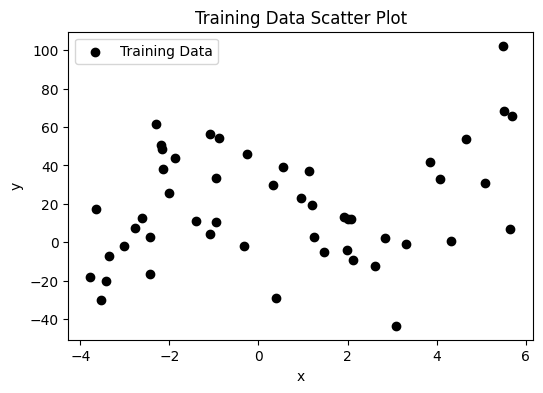

Baseline Model: y = 17.2049 + 2.5907*x
Train R2: 0.0649, Train MSE: 791.4167

Nonlinear Model: y = 12.9445 + 1.6056*x + 0.5618*x^2
Train R2: 0.0853, Train MSE: 774.1273



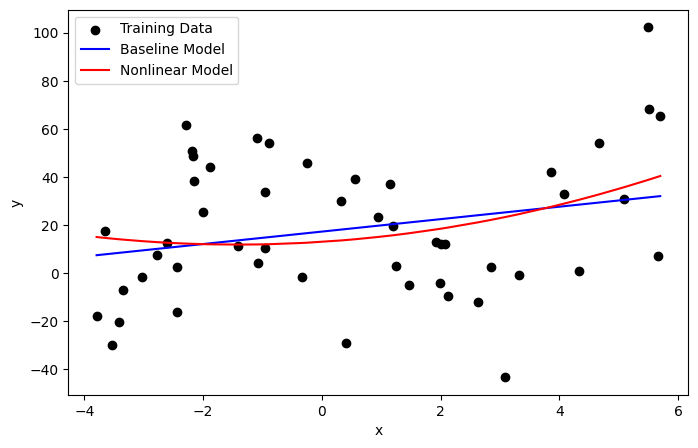

Baseline Test R2: -0.1329, Test MSE: 1116.6632
Nonlinear Test R2: -0.1203, Test MSE: 1104.2014


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

path = './data/'
train = pd.read_csv(path + 'A2_Q7_train.csv')
test = pd.read_csv(path + 'A2_Q7_test.csv')

x_train = train.x.values
y_train = train.y.values

x_test = test.x.values
y_test = test.y.values

# (a) Scatter plot of training data
plt.figure(figsize=(6, 4))
plt.scatter(x_train, y_train, color='black', label='Training Data')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Training Data Scatter Plot')
plt.legend()
plt.show()

# (b) Baseline linear regression model (y = a0 + a1*x)
X_train_b = x_train.reshape(-1, 1)
model_b = LinearRegression()
model_b.fit(X_train_b, y_train)

y_train_pred_b = model_b.predict(X_train_b)
r2_b = r2_score(y_train, y_train_pred_b)
mse_b = mean_squared_error(y_train, y_train_pred_b)

print(f"Baseline Model: y = {model_b.intercept_:.4f} + {model_b.coef_[0]:.4f}*x")
print(f"Train R2: {r2_b:.4f}, Train MSE: {mse_b:.4f}\n")

# (c) Nonlinear transformation model (e.g., quadratic: y = a0 + a1*x + a2*x^2)
X_train_c = np.column_stack((x_train, x_train**2))
model_c = LinearRegression()
model_c.fit(X_train_c, y_train)

y_train_pred_c = model_c.predict(X_train_c)
r2_c = r2_score(y_train, y_train_pred_c)
mse_c = mean_squared_error(y_train, y_train_pred_c)

print(f"Nonlinear Model: y = {model_c.intercept_:.4f} + {model_c.coef_[0]:.4f}*x + {model_c.coef_[1]:.4f}*x^2")
print(f"Train R2: {r2_c:.4f}, Train MSE: {mse_c:.4f}\n")

# (d) Visualize model fits on training data
plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, color='black', label='Training Data')
sort_idx = np.argsort(x_train)
plt.plot(x_train[sort_idx], y_train_pred_b[sort_idx], color='blue', label='Baseline Model')
plt.plot(x_train[sort_idx], y_train_pred_c[sort_idx], color='red', label='Nonlinear Model')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

# (e) Evaluate generalization performance on test data
X_test_b = x_test.reshape(-1, 1)
y_test_pred_b = model_b.predict(X_test_b)
test_r2_b = r2_score(y_test, y_test_pred_b)
test_mse_b = mean_squared_error(y_test, y_test_pred_b)

X_test_c = np.column_stack((x_test, x_test**2))
y_test_pred_c = model_c.predict(X_test_c)
test_r2_c = r2_score(y_test, y_test_pred_c)
test_mse_c = mean_squared_error(y_test, y_test_pred_c)

print(f"Baseline Test R2: {test_r2_b:.4f}, Test MSE: {test_mse_b:.4f}")
print(f"Nonlinear Test R2: {test_r2_c:.4f}, Test MSE: {test_mse_c:.4f}")

**ANSWER**

(f)

Training Data: The nonlinear model performs slightly better than the baseline linear model on the training data, yielding a higher $R^2$ ($0.0853$ vs. $0.0649$) and a lower MSE ($774.13$ vs. $791.42$). This is because adding a quadratic term ($x^2$) grants the model more flexibility to fit the slight upward curvature in the scatter plot.

Test Data: Both models show extremely low (and even negative) $R^2$ values (Baseline Test $R^2 = -0.1329$, Nonlinear Test $R^2 = -0.1203$), indicating poor predictive performance overall. However, the nonlinear model still achieves a slightly lower Test MSE ($1104.20$ vs. $1116.66$), meaning it generalizes marginally better, though the data's high variance and noise make accurate prediction difficult for both models.

(g)

Impact: The predictive capability and generalization accuracy would degrade even further, leading to significantly higher prediction errors and more negative $R^2$ values.

Why: Supervised learning models rely on the fundamental assumption that training and test datasets are drawn from the same underlying probability distribution (the I.I.D. assumption). If the test data distribution differs significantly from the training data, the learned coefficients and fitted curves will no longer represent the new data relationships, causing the model's predictions to fail completely.

AI Use Appendix
Tool name: Gemini3.1 (Google)

Exact prompts used:

"Please proofread and refine the grammar to make it academic and rigorous."

"Are there any functions in [library/module name] that serve a role similar to [specific purpose]? If so, please provide an explanation and a brief example."

"Please explain the root cause of this error."

Brief reflection:
I utilized the AI to refine and elevate my drafts into rigorous, academic English suitable for a formal report. Additionally, I consulted the AI to clarify specific programming functions and their roles, as well as to diagnose and troubleshoot runtime errors encountered during code execution. I carefully reviewed and integrated these insights to finalize my code and final write-up.